In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("EDA libraries imported successfully!")


EDA libraries imported successfully!


In [2]:

df = pd.read_csv("airfare_data.csv")

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (300153, 11)


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [3]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  str    
 1   flight            300153 non-null  str    
 2   source_city       300153 non-null  str    
 3   departure_time    300153 non-null  str    
 4   stops             300153 non-null  str    
 5   arrival_time      300153 non-null  str    
 6   destination_city  300153 non-null  str    
 7   class             300153 non-null  str    
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 40.6 MB


In [4]:

missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

missing_df


,Missing Values,Missing Percentage
airline,0,0.0
flight,0,0.0
source_city,0,0.0
departure_time,0,0.0
stops,0,0.0
arrival_time,0,0.0
destination_city,0,0.0
class,0,0.0
duration,0,0.0
days_left,0,0.0


In [5]:

print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [6]:

df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
airline,300153,6,Vistara,127859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight,300153,1561,UK-706,3235,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_city,300153,6,Delhi,61343,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_time,300153,6,Morning,71146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stops,300153,3,one,250863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_time,300153,6,Night,91538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_city,300153,6,Mumbai,59097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,300153,2,Economy,206666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,300153.0,NaN,NaN,NaN,12.221021,7.191997,0.83,6.83,11.25,16.17,49.83
days_left,300153.0,NaN,NaN,NaN,26.004751,13.561004,1.0,15.0,26.0,38.0,49.0


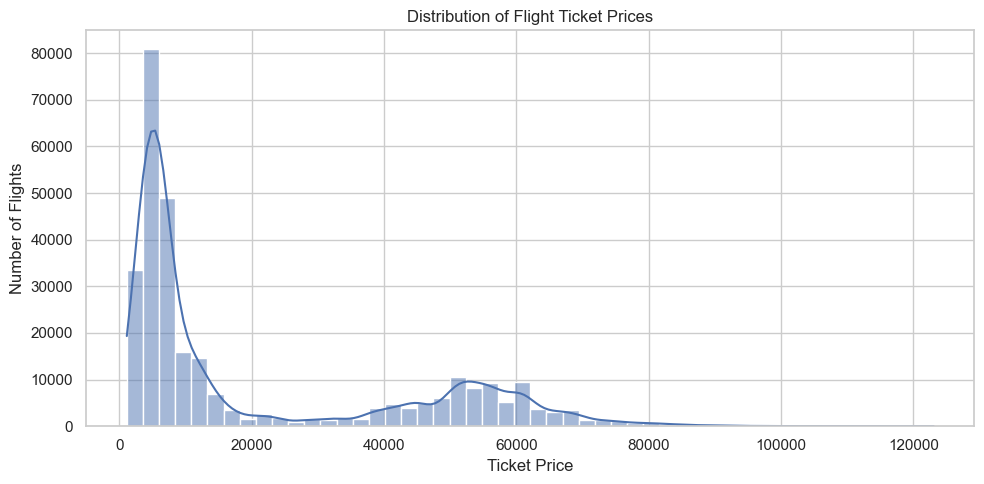

In [ ]:

#Flight price distribution

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="price", bins=50, kde=True)

plt.title("Distribution of Flight Ticket Prices")
plt.xlabel("Ticket Price")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()


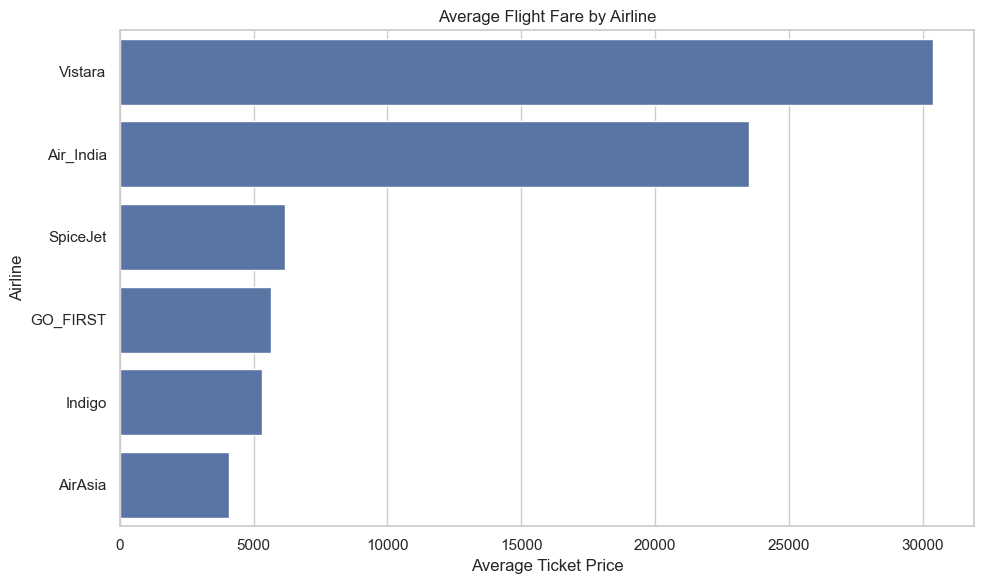

In [8]:
#Average fare by airline


airline_prices = (
    df.groupby("airline", as_index=False)["price"]
    .mean()
    .sort_values("price", ascending=False)
)

sns.barplot(data=airline_prices, x="price", y="airline")

plt.title("Average Flight Fare by Airline")
plt.xlabel("Average Ticket Price")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()


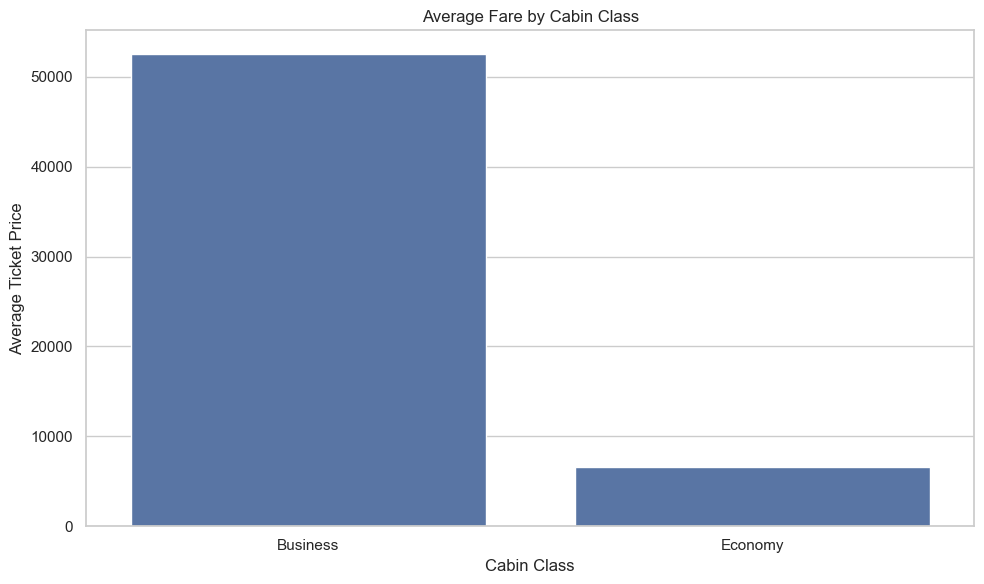

In [9]:
#Economy vs Business


class_prices = (
    df.groupby("class", as_index=False)["price"]
    .mean()
    .sort_values("price", ascending=False)
)

sns.barplot(data=class_prices, x="class", y="price")

plt.title("Average Fare by Cabin Class")
plt.xlabel("Cabin Class")
plt.ylabel("Average Ticket Price")
plt.tight_layout()
plt.show()


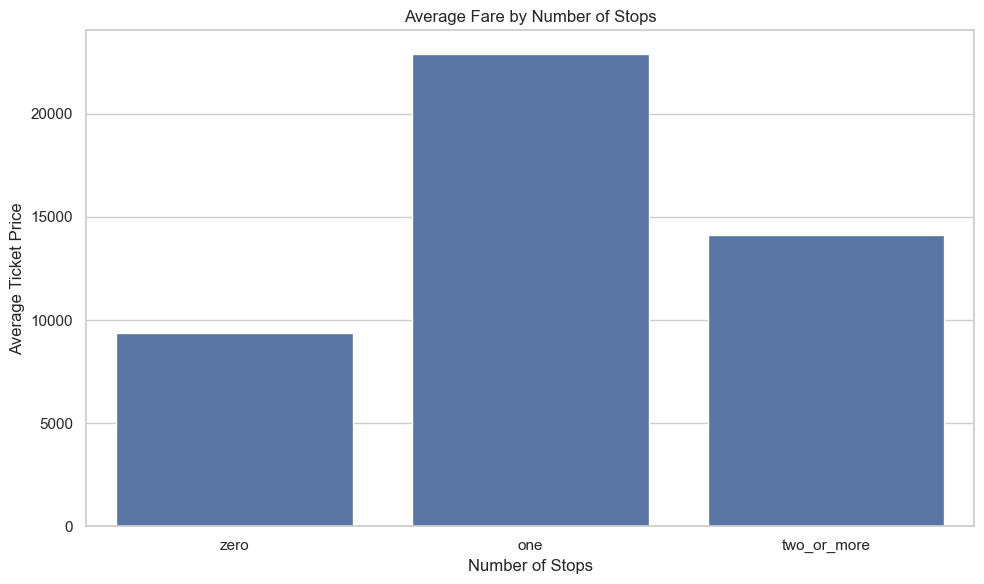

In [10]:
#Fare by number of stops


sns.barplot(data=df, x="stops", y="price", errorbar=None)

plt.title("Average Fare by Number of Stops")
plt.xlabel("Number of Stops")
plt.ylabel("Average Ticket Price")
plt.tight_layout()
plt.show()


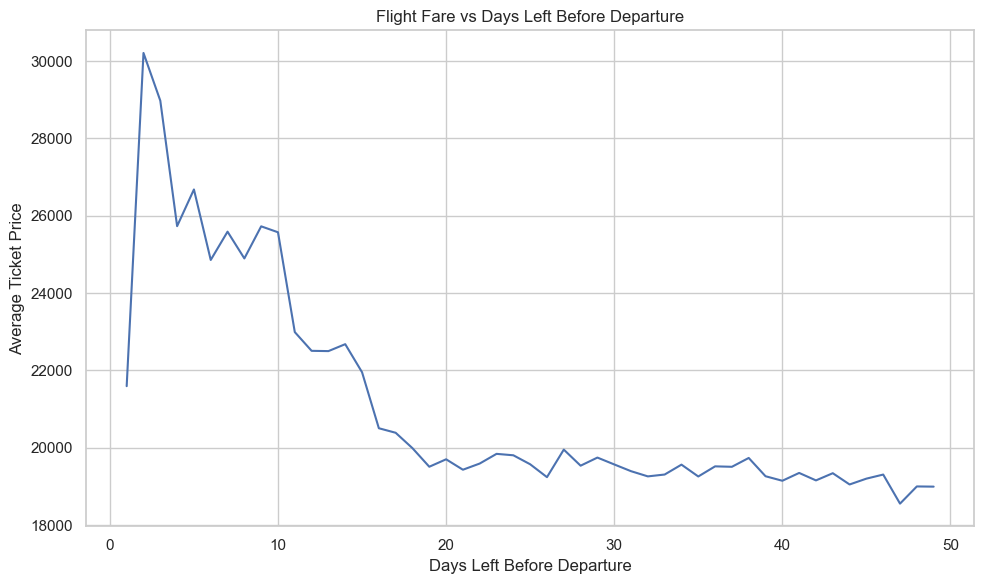

In [11]:
#Fare vs days left


sns.lineplot(data=df, x="days_left", y="price", errorbar=None)

plt.title("Flight Fare vs Days Left Before Departure")
plt.xlabel("Days Left Before Departure")
plt.ylabel("Average Ticket Price")
plt.tight_layout()
plt.show()


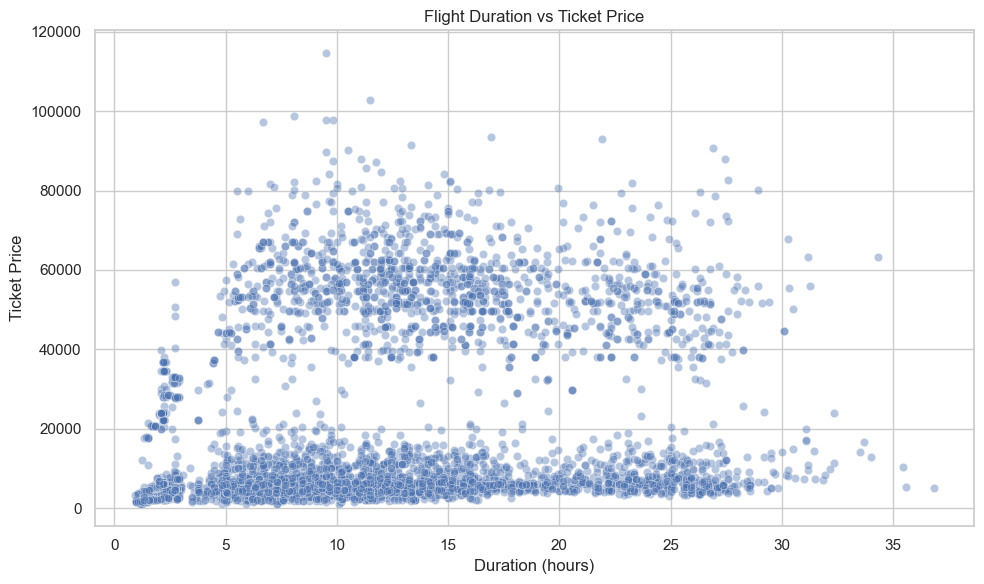

In [12]:
#Fare vs duration


sns.scatterplot(
    data=df.sample(n=min(5000, len(df)), random_state=42),
    x="duration",
    y="price",
    alpha=0.4
)

plt.title("Flight Duration vs Ticket Price")
plt.xlabel("Duration (hours)")
plt.ylabel("Ticket Price")
plt.tight_layout()
plt.show()


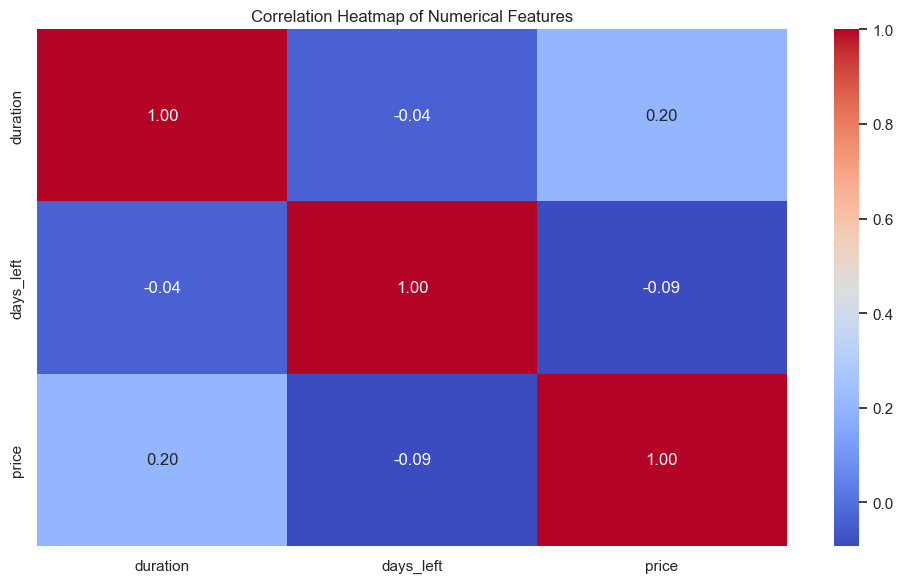

In [13]:
#Correlation analysis


numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()
